# NYC Collision Heatmaps and Inferred Camera Locations

**2021–2025 · All five boroughs · Descriptive spatial analysis**

This notebook uses the complete selected-date extracts cached with this project. All maps and tables are local. It does not estimate causal camera effects, driving risk, physical camera counts, or installation dates.

## tl;dr

The executed summary below distinguishes data volume, mapping coverage, and inferred enforcement locations. A ticket location is evidence of enforcement activity at an approximate intersection or address. It is not a verified camera pole.

In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'make_maps.py').exists():
    ROOT = ROOT / 'camera-location-analysis'
sys.path.insert(0, str(ROOT))
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache' / 'matplotlib')
DATA = ROOT / 'data' / 'processed'
QUALITY = ROOT / 'outputs' / 'quality'
PERIOD_START, PERIOD_END_EXCLUSIVE = '2021-01-01', '2026-01-01'
GRID_SIZE_METERS, ANALYSIS_CRS = 250, 'EPSG:26918'
annual = pd.read_csv(QUALITY / 'annual_count_reconciliation.csv')
summary = annual.groupby('measure')[['unique_records', 'mapped_records']].sum()
summary['mapping_coverage'] = summary.mapped_records / summary.unique_records
display(summary.style.format({'unique_records':'{:,.0f}', 'mapped_records':'{:,.0f}', 'mapping_coverage':'{:.1%}'}))
sites = pd.read_csv(ROOT / 'outputs' / 'inferred_camera_locations.csv')
display(sites.groupby(['camera_type', 'borough']).size().unstack(fill_value=0).rename_axis('Inferred enforcement locations'))


,unique_records,mapped_records,mapping_coverage
measure,,,
crashes,"487,914","449,308",92.1%
persons,"1,697,877","1,549,051",91.2%
tickets_all,"80,714,373","65,104,669",80.7%
tickets_red_light,"3,203,371","2,391,654",74.7%
tickets_speed,"25,763,870","21,784,534",84.6%
vehicles,"985,702","907,515",92.1%


borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
Inferred enforcement locations,,,,,
red_light,25,85,12,77,30
speed,382,926,224,793,268


## Context & Methods

The research question for this phase is: **Where are recorded collisions, involved people, involved vehicles, and issued tickets concentrated, and which enforcement locations can be inferred from camera tickets?**

Each map counts a different unit. Person includes uninjured people. Person and Vehicles are independently joined to a unique Crashes table using `collision_id`. Tickets are deduplicated across fiscal files using `summons_number`; the latest source fiscal year wins when versions conflict. All ticket filtering uses `issue_date`, not the fiscal-year label.

### Key Assumptions

- Source records dated January 1, 2021–December 31, 2025 define study membership. Collision detail dates define their annual panels; any disagreement with the parent crash is audited.
- Coordinates are projected into NAD83 / UTM zone 18N (EPSG:26918). Grid origin is the CRS origin, and cell indices use floor division by 250 m. Boundary checks include water areas so valid bridge records are retained.
- LION is the supplied street-network snapshot, not a historical reconstruction for each study year. Address interpolation is approximate.
- Camera type is based on code 36 (speed) or 7 (red light). Inference additionally requires issuing agency V (NYC Department of Transportation) and a consistent or missing description. Contradictory records are retained in the quality exports.
- Camera text columns are reconstructed before parsing; both joined-word and spaced variants must be checked against LION. Directions, boroughs, service-road wording, and Queens hyphens are preserved.
- Intersection matching requires a shared LION node and road level. Closely grouped nodes may represent one junction; widely separated candidates remain unresolved. Explicit service-road text is never silently collapsed to a highway.
- Ticket volume does not determine geographic matching quality. No low-volume candidate is excluded solely for low counts. No centroid fallback is used.
- Missing coordinates are not zero events. Count concentrations are not exposure-adjusted rates, and apparent annual differences may reflect reporting or mapping changes.

### Reproduce or rebuild

The default notebook run uses frozen local extracts, checks reconciliation, and regenerates every map. Editable plotting code is in `make_maps.py`; geocoding and processing are in the adjacent Python modules. To repeat downloads or geocoding, follow `README.md` and use `run_pipeline.py`. The complete raw extracts and large unresolved-record tables stay in the local project; they are not silently replaced by samples.

The Python environment is isolated in `.venv`, with exact installed versions in `requirements.lock.txt`. Source queries, row counts, timestamps, and partition hashes are saved under `data/metadata` and alongside each raw Parquet partition.

## Data

Official NYC Open Data sources: [Crashes](https://data.cityofnewyork.us/d/h9gi-nx95), [Person](https://data.cityofnewyork.us/d/f55k-p6yu), [Vehicles](https://data.cityofnewyork.us/d/bm4k-52h4), and the [annual Parking Violations Issued collection](https://data.cityofnewyork.us/browse?Data-Collection_Data-Collection=DOF+Parking+Violations+Issued). FY2014–FY2027 identities and selected-period counts were checked. Earlier files contain a small number of anomalous future-dated records; later files contain backdated records. These are retained and flagged.

Spatial reference: the user-supplied LION geodatabase; official [borough land boundaries](https://data.cityofnewyork.us/d/gthc-hcne) and [borough boundaries including water](https://data.cityofnewyork.us/d/wh2p-dxnf). Interpretation follows the [LION metadata](https://s-media.nyc.gov/agencies/dcp/assets/files/pdf/data-tools/bytes/lion_metadata.pdf) and the [NYC violation-code definitions](https://www.nyc.gov/site/finance/vehicles/services-violation-codes.page).

In [2]:
sources = pd.read_csv(QUALITY / 'source_period_reconciliation.csv')
source_summary = sources.groupby(['source', 'dataset_id']).agg(
    expected_rows=('expected_source_rows','sum'),
    downloaded_rows=('downloaded_rows','sum'),
    all_partitions_complete=('complete','all'))
display(source_summary.style.format({'expected_rows':'{:,.0f}', 'downloaded_rows':'{:,.0f}'}))
assert source_summary.all_partitions_complete.all()


,,expected_rows,downloaded_rows,all_partitions_complete
source,dataset_id,,,
crashes,h9gi-nx95,"487,914","487,914",True
persons,f55k-p6yu,"1,697,877","1,697,877",True
tickets_fy2014,jt7v-77mi,91,91,True
tickets_fy2016,kiv2-tbus,71,71,True
tickets_fy2017,2bnn-yakx,40,40,True
tickets_fy2018,a5td-mswe,15,15,True
tickets_fy2019,faiq-9dfq,23,23,True
tickets_fy2020,p7t3-5i9s,257,257,True
tickets_fy2021,kvfd-bves,"6,943,117","6,943,117",True


### Validate joins and counts

A clean run checks source partition counts and checksums, ticket uniqueness, camera category totals, and grid totals. Large unresolved and conflicting records are retained as Parquet; compact summaries and unresolved camera addresses are also supplied as CSV.

In [3]:
from validate_analysis import validate
annual, borough_coverage, validation = validate()
display(annual[['measure','year','unique_records','mapped_records','mapping_coverage','grid_reconciles']].style.format(
    {'unique_records':'{:,.0f}', 'mapped_records':'{:,.0f}', 'mapping_coverage':'{:.1%}'}))
assert validation['failed'] == 0


{
  "passed": 377,
  "failed": 0,
  "checks": 377,
  "limitations": [
    "Manual review checks local address/topology consistency, not pole positions or independent installation records.",
    "Conservative unresolved service-road and complex-junction matches reduce coverage.",
    "LION is the supplied modern snapshot rather than year-specific historical streets.",
    "No traffic exposure denominators; count hotspots cannot be interpreted as rates or causal effects."
  ]
}


,measure,year,unique_records,mapped_records,mapping_coverage,grid_reconciles
0,crashes,2021,"110,558","100,883",91.2%,True
1,crashes,2022,"103,887","93,063",89.6%,True
2,crashes,2023,"96,607","88,995",92.1%,True
3,crashes,2024,"91,316","83,679",91.6%,True
4,crashes,2025,"85,546","82,688",96.7%,True
5,persons,2021,"386,128","348,501",90.3%,True
6,persons,2022,"362,579","320,374",88.4%,True
7,persons,2023,"339,159","308,350",90.9%,True
8,persons,2024,"317,941","288,607",90.8%,True
9,persons,2025,"292,070","283,219",97.0%,True


## Results

Each cumulative map has its own count scale. Within each five-panel annual figure, the color scale is shared across all five years. Colors use a logarithmic scale with actual count labels. The same extent, CRS, and grid alignment are used throughout.

In [4]:
from make_maps import Maps
maps = Maps()


### Unique collisions

Only successfully located records contribute to the spatial cells.

Exported crashes_cumulative_2021_2025.png


Exported crashes_annual_2021_2025.png


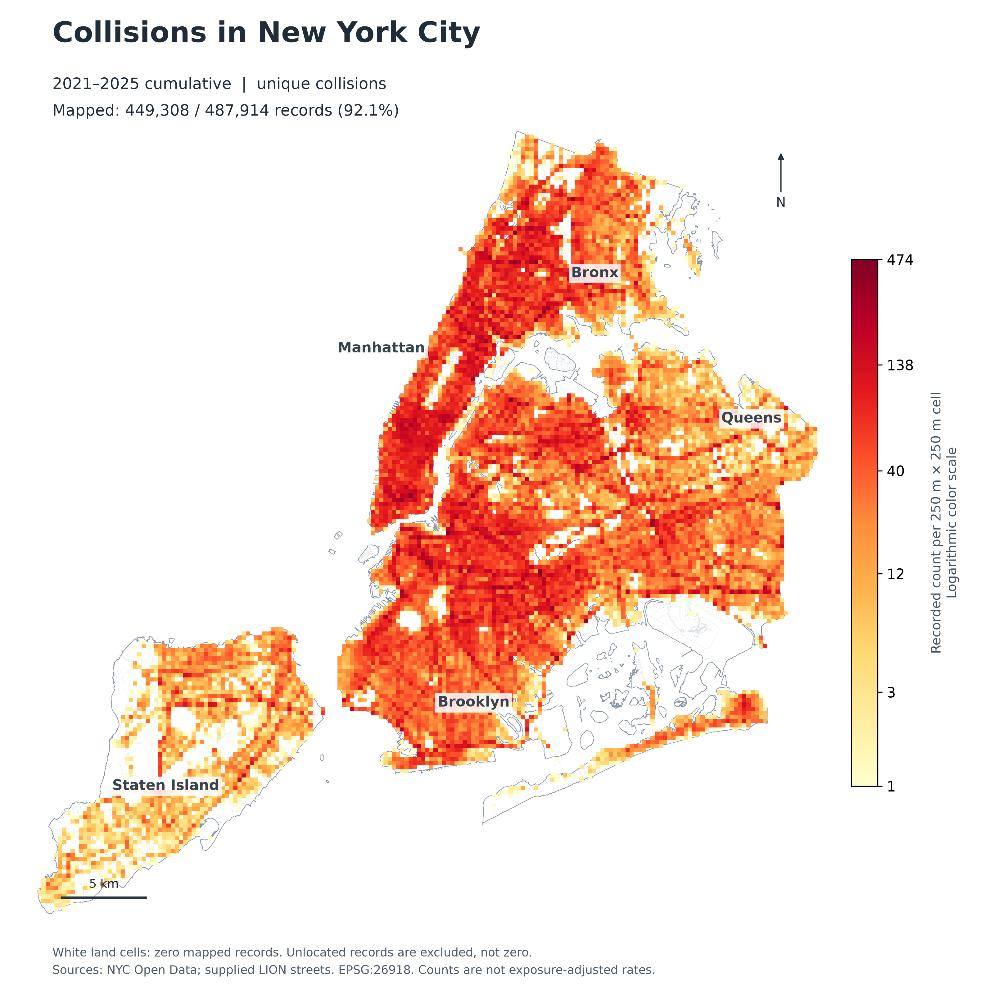

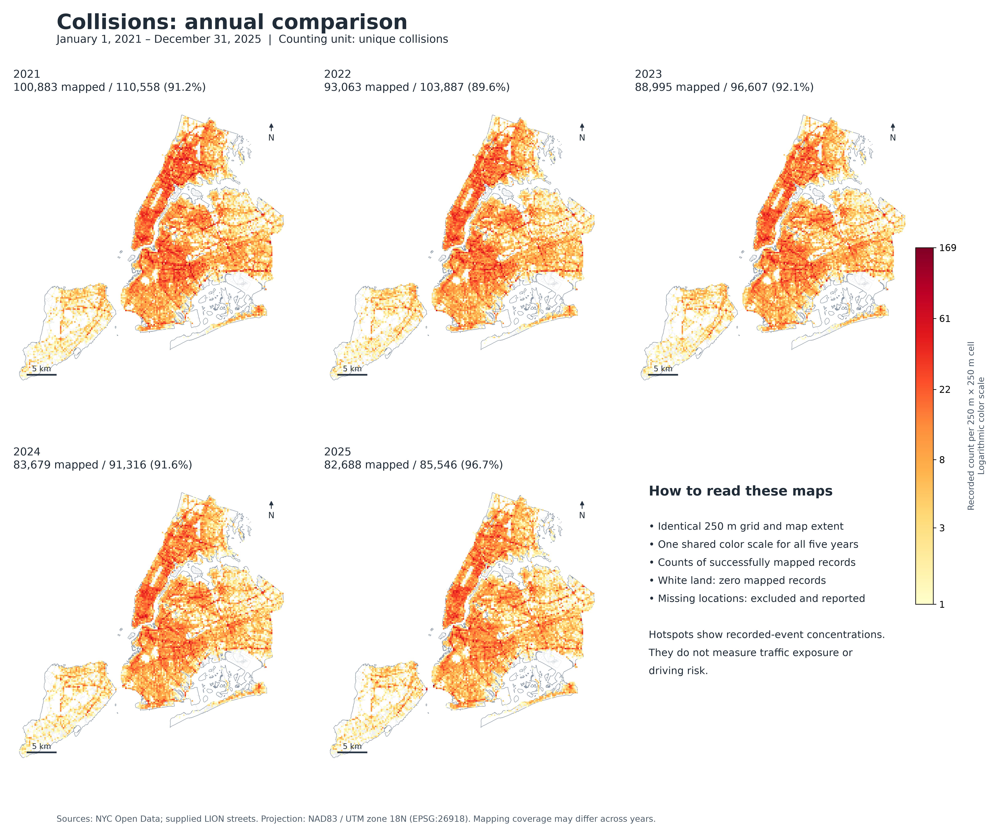

In [5]:
maps.heatmaps('crashes')
display(Image(filename=str(ROOT / 'outputs/maps/crashes_cumulative_2021_2025.png'), width=950))
display(Image(filename=str(ROOT / 'outputs/maps/crashes_annual_2021_2025.png'), width=1200))


### Involved-person records

These counts inherit the location of the parent crash; they are not independent crash events.

Exported persons_cumulative_2021_2025.png


Exported persons_annual_2021_2025.png


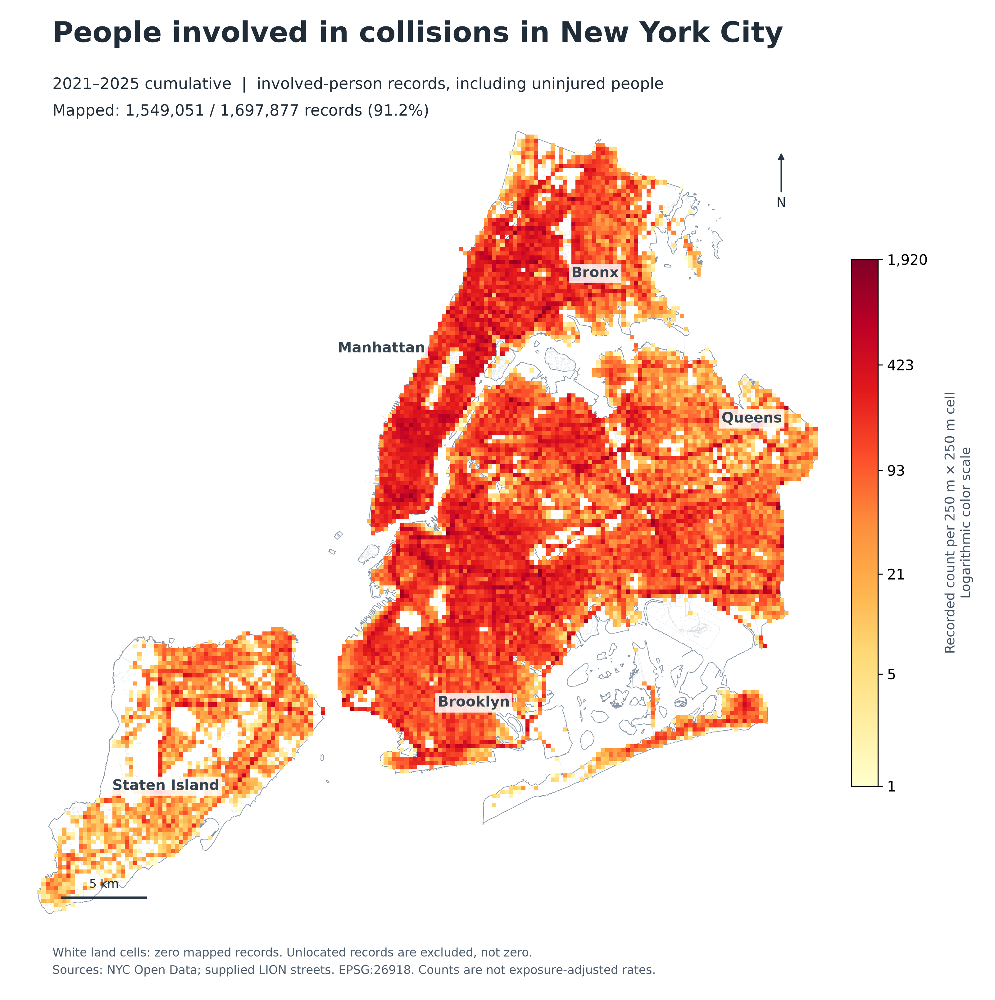

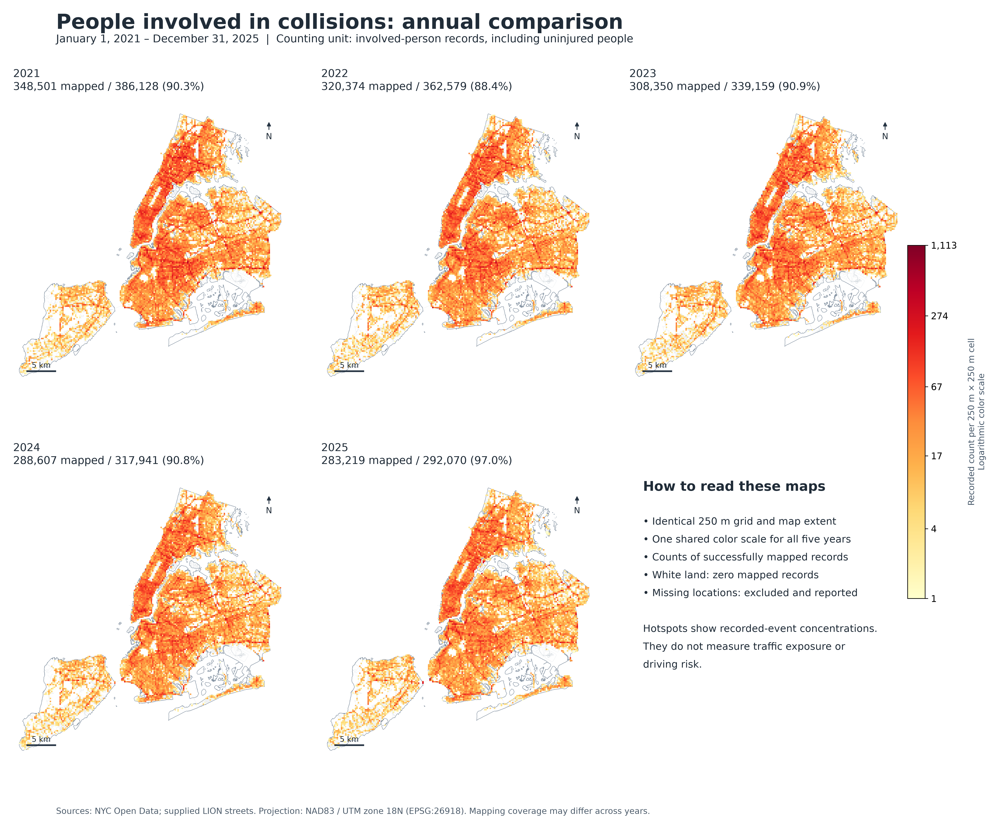

In [6]:
maps.heatmaps('persons')
display(Image(filename=str(ROOT / 'outputs/maps/persons_cumulative_2021_2025.png'), width=950))
display(Image(filename=str(ROOT / 'outputs/maps/persons_annual_2021_2025.png'), width=1200))


### Involved-vehicle records

These counts inherit the location of the parent crash; they are not independent crash events.

Exported vehicles_cumulative_2021_2025.png


Exported vehicles_annual_2021_2025.png


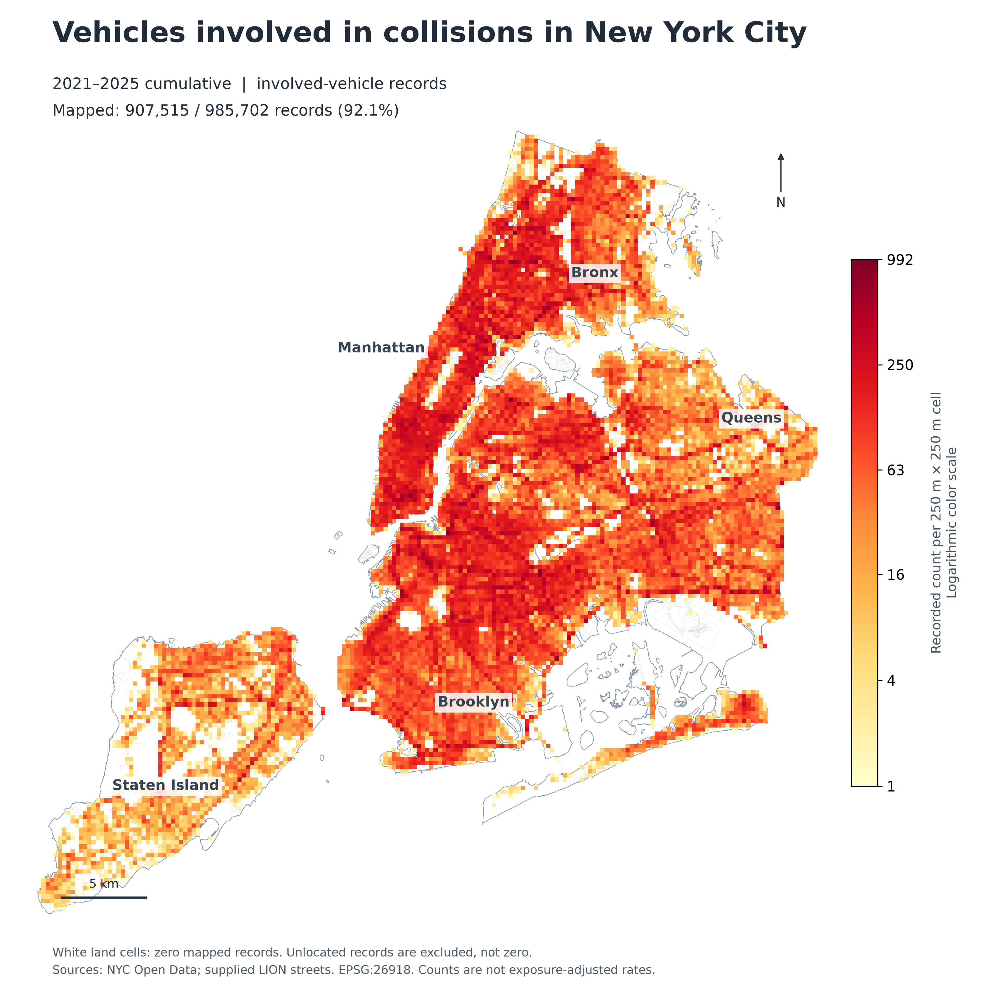

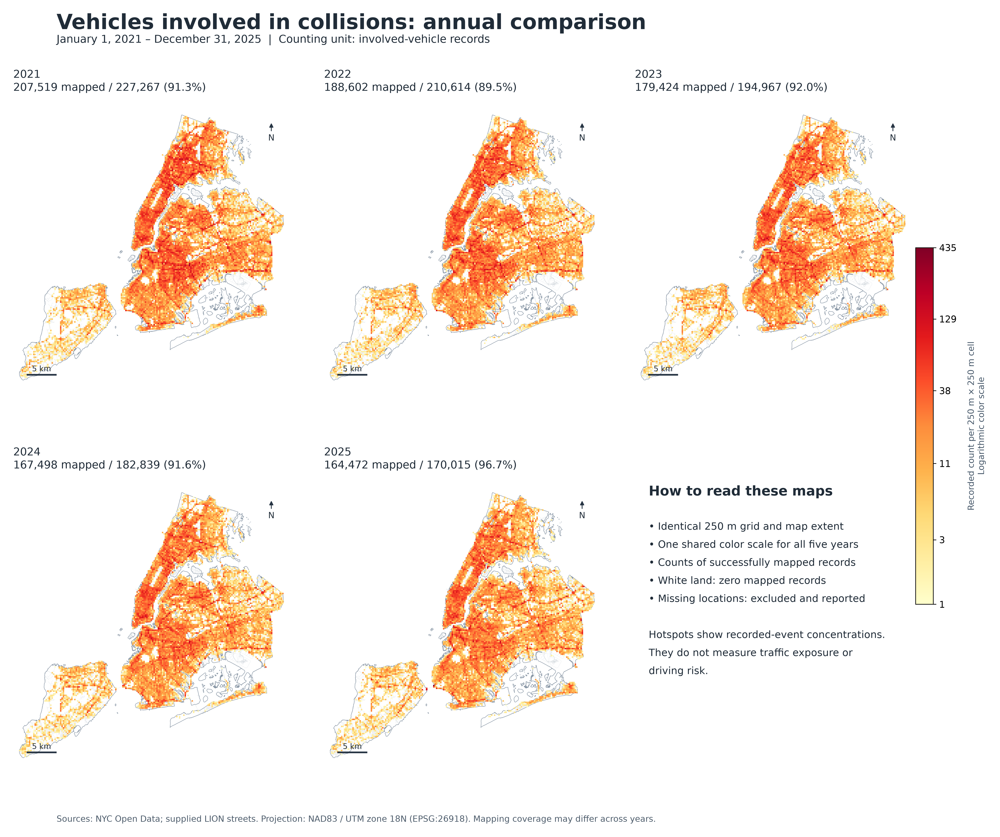

In [7]:
maps.heatmaps('vehicles')
display(Image(filename=str(ROOT / 'outputs/maps/vehicles_cumulative_2021_2025.png'), width=950))
display(Image(filename=str(ROOT / 'outputs/maps/vehicles_annual_2021_2025.png'), width=1200))


### All unique issued tickets

Only successfully located records contribute to the spatial cells.

Exported tickets_all_cumulative_2021_2025.png


Exported tickets_all_annual_2021_2025.png


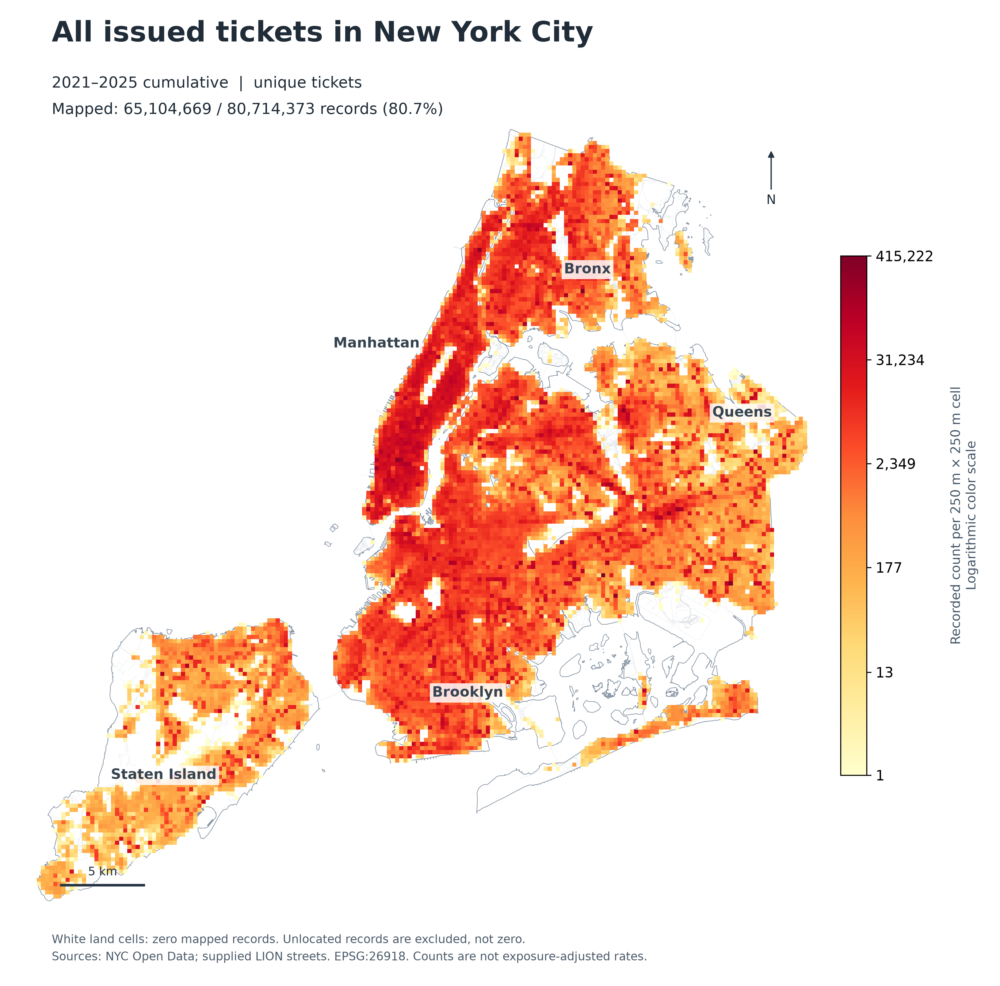

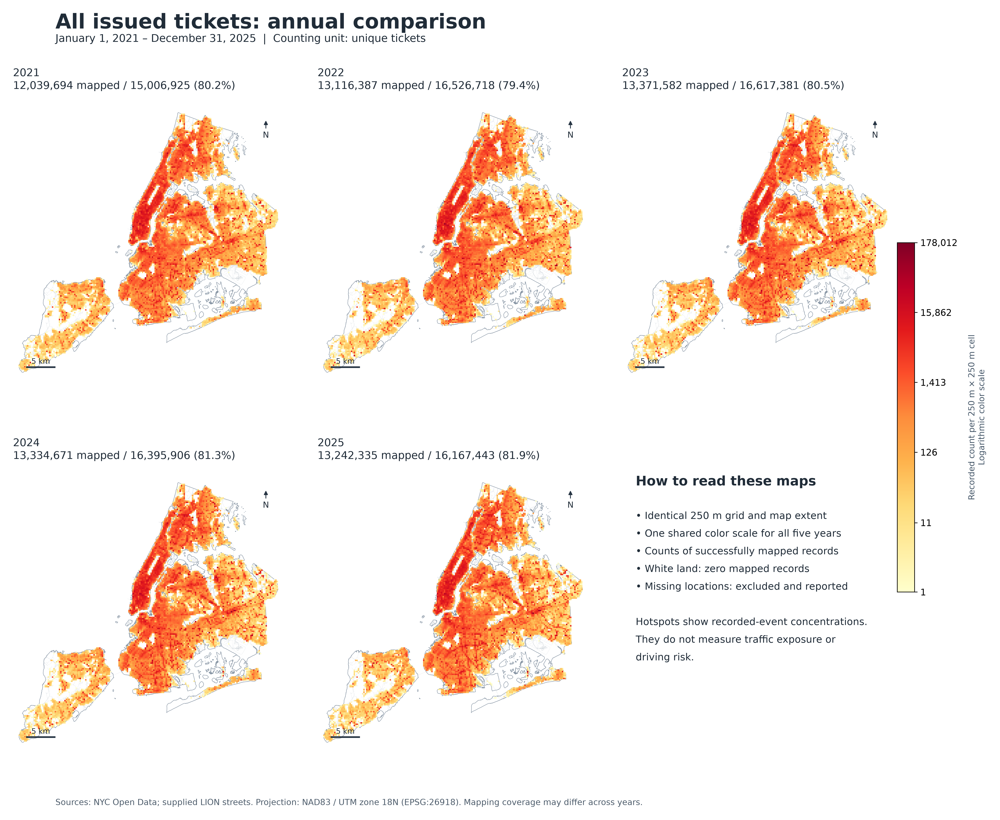

In [8]:
maps.heatmaps('tickets_all')
display(Image(filename=str(ROOT / 'outputs/maps/tickets_all_cumulative_2021_2025.png'), width=950))
display(Image(filename=str(ROOT / 'outputs/maps/tickets_all_annual_2021_2025.png'), width=1200))


### Speed-camera-category tickets

Only successfully located records contribute to the spatial cells.

Exported tickets_speed_cumulative_2021_2025.png


Exported tickets_speed_annual_2021_2025.png


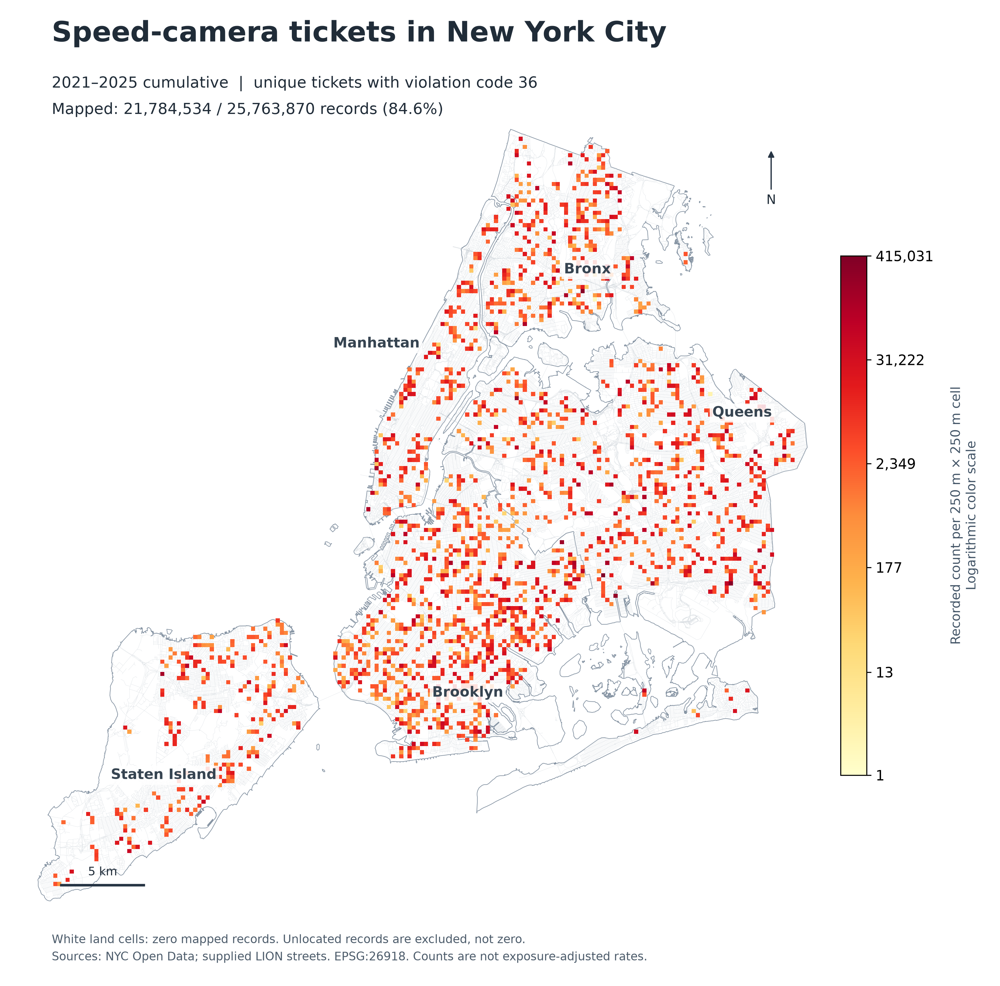

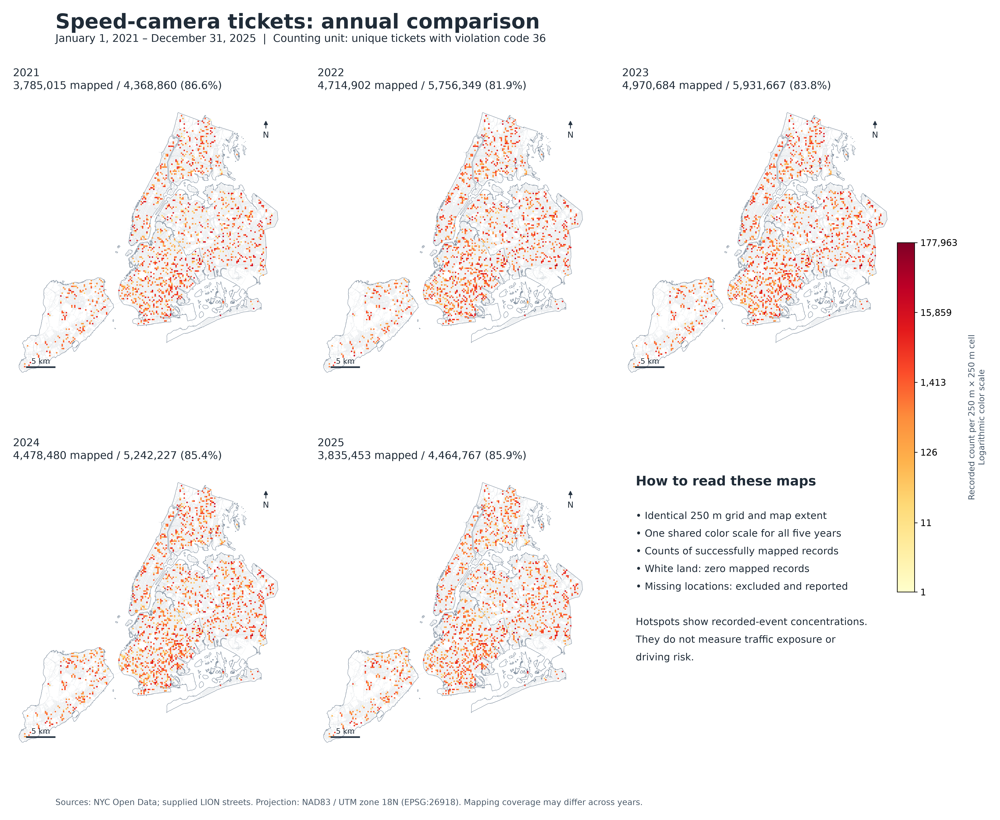

In [9]:
maps.heatmaps('tickets_speed')
display(Image(filename=str(ROOT / 'outputs/maps/tickets_speed_cumulative_2021_2025.png'), width=950))
display(Image(filename=str(ROOT / 'outputs/maps/tickets_speed_annual_2021_2025.png'), width=1200))


### Red-light-camera-category tickets

Only successfully located records contribute to the spatial cells.

Exported tickets_red_light_cumulative_2021_2025.png


Exported tickets_red_light_annual_2021_2025.png


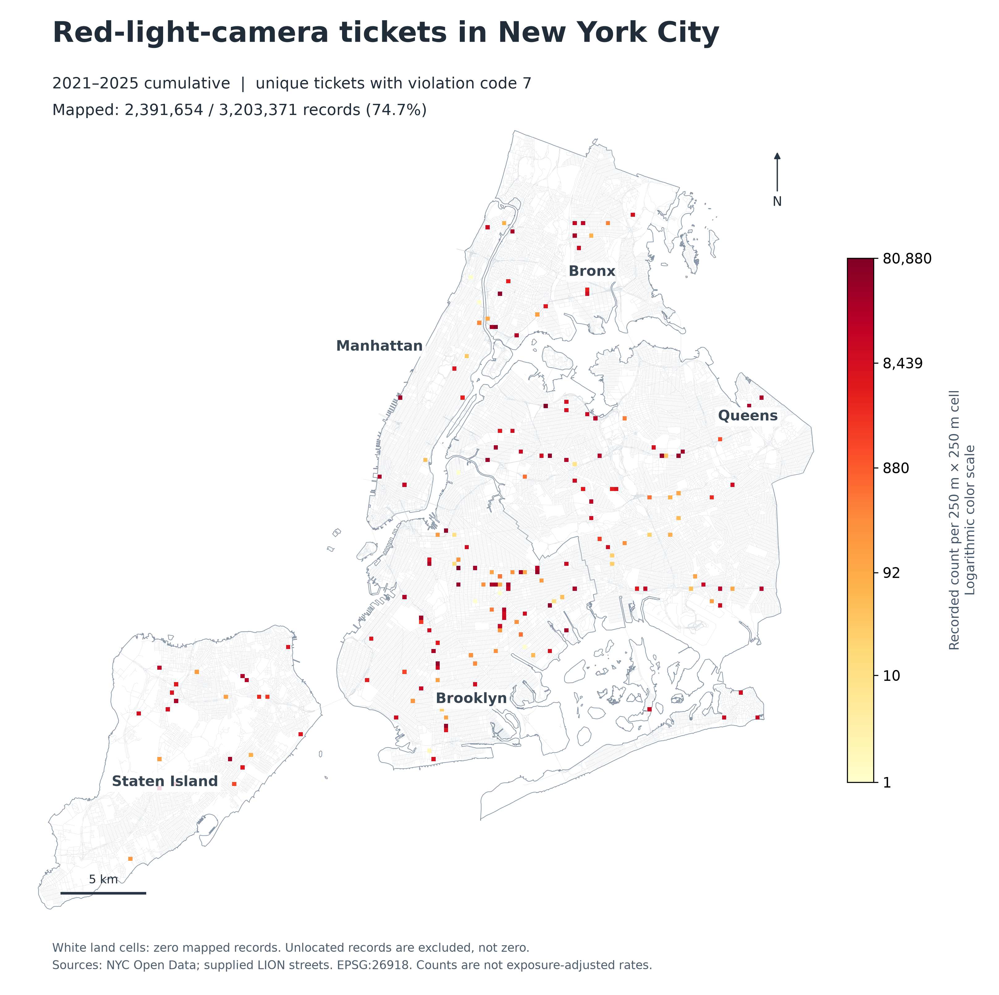

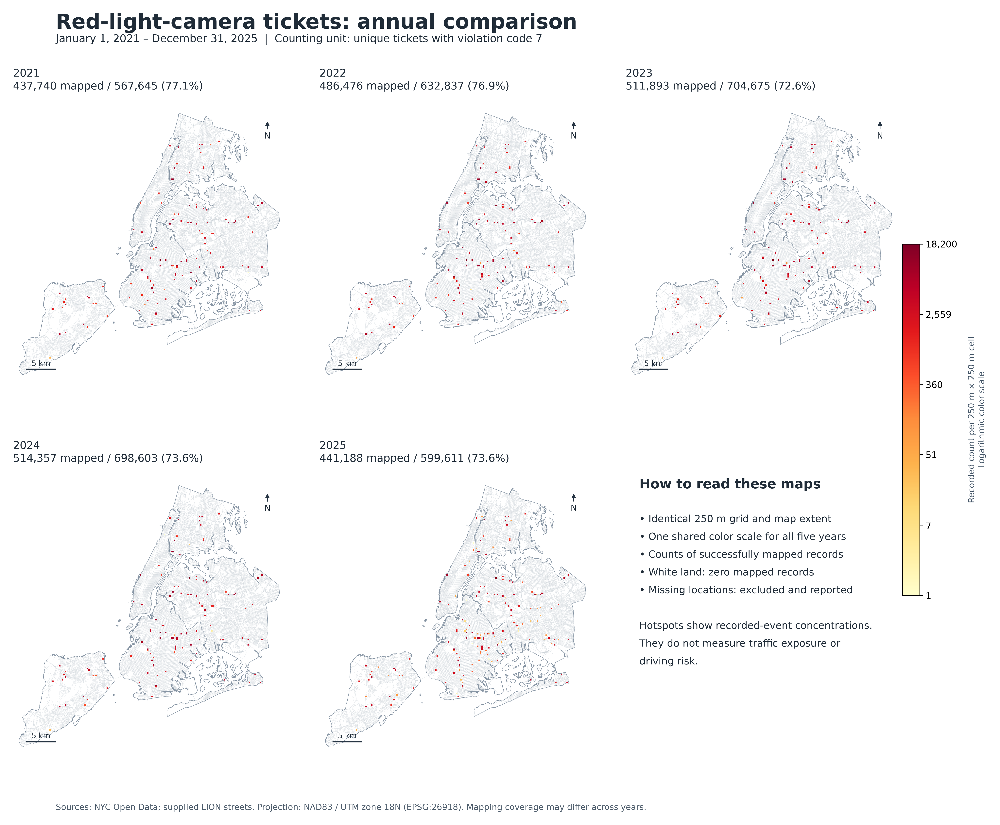

In [10]:
maps.heatmaps('tickets_red_light')
display(Image(filename=str(ROOT / 'outputs/maps/tickets_red_light_cumulative_2021_2025.png'), width=950))
display(Image(filename=str(ROOT / 'outputs/maps/tickets_red_light_annual_2021_2025.png'), width=1200))


### Inferred enforcement locations and collision overlays

Speed and red-light sites remain separate, as do different recorded directions at the same intersection. Markers have constant size. Coincident points may overlap visually; the CSV and GeoJSON preserve the separate records. The geographic-match fields describe precision independently of supporting ticket counts.

Direction is retained from ticket text and does not identify the verified enforced carriageway within a junction. Normalized street fields are matching keys, not official postal names: for example, leading ST becomes STREET, so original ST JOHN AVE should be read as Saint John Avenue. Original address examples are preserved.

Exported inferred_speed_locations.png


Exported inferred_speed_locations_collision_overlay.png


Exported inferred_red_light_locations.png


Exported inferred_red_light_locations_collision_overlay.png


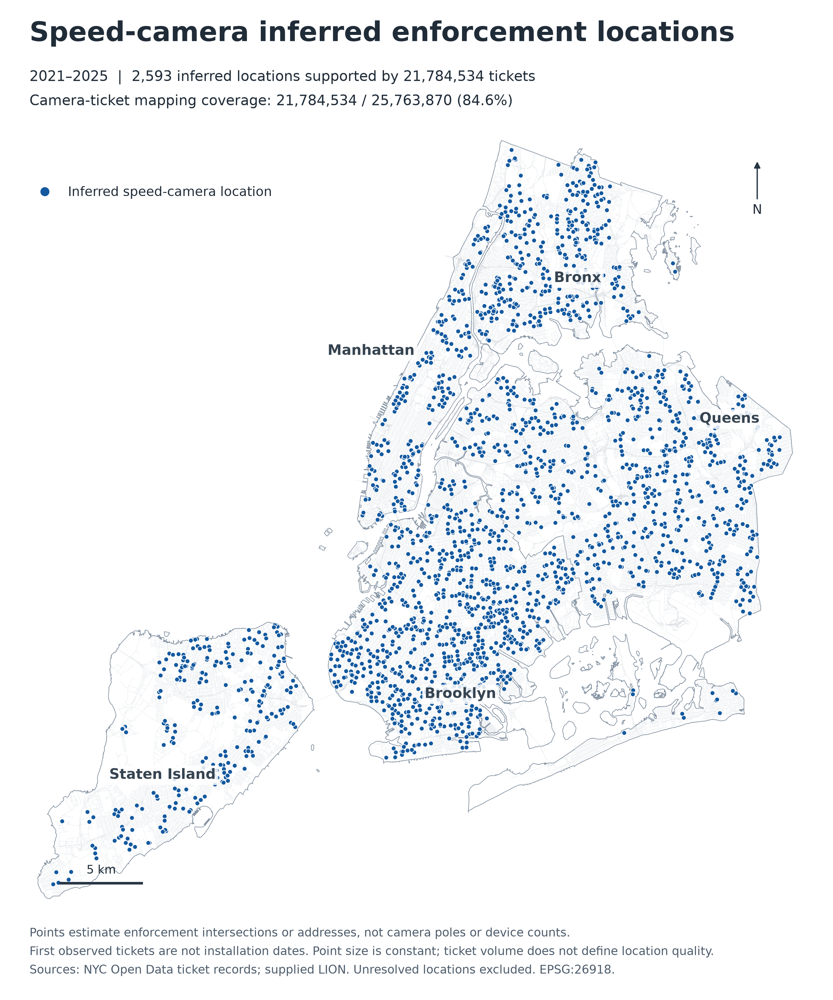

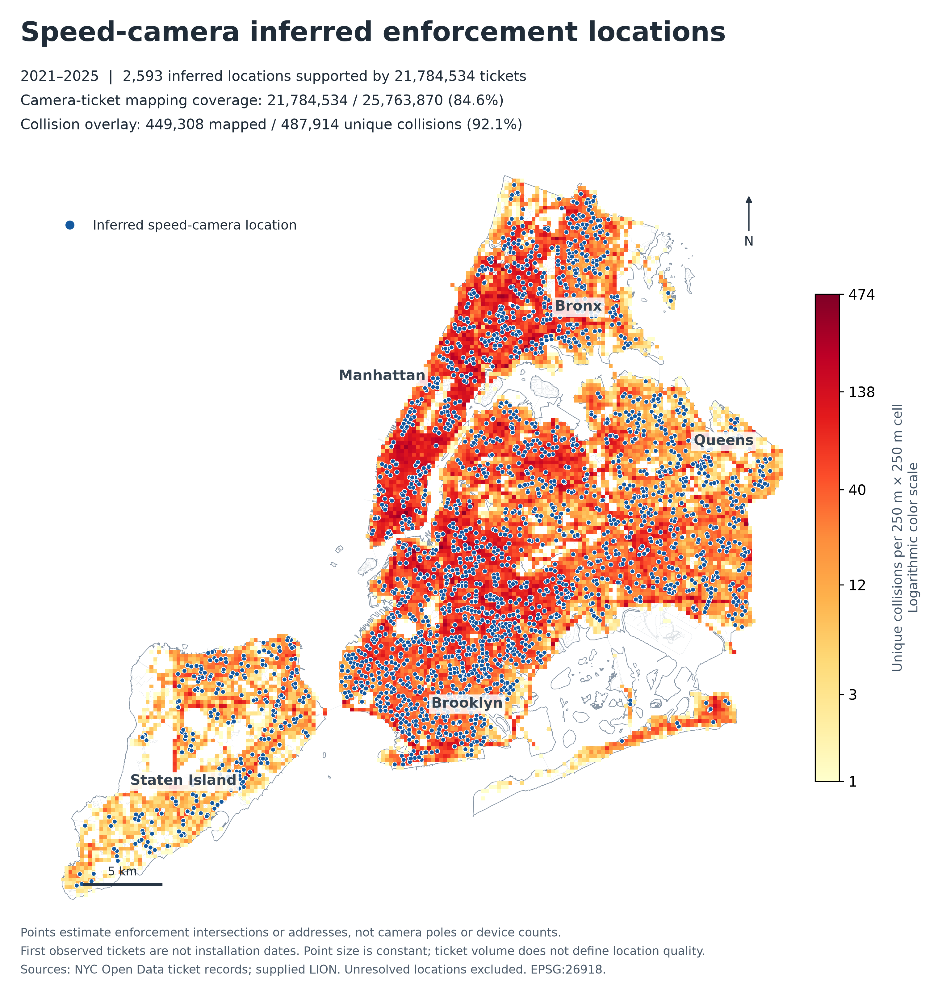

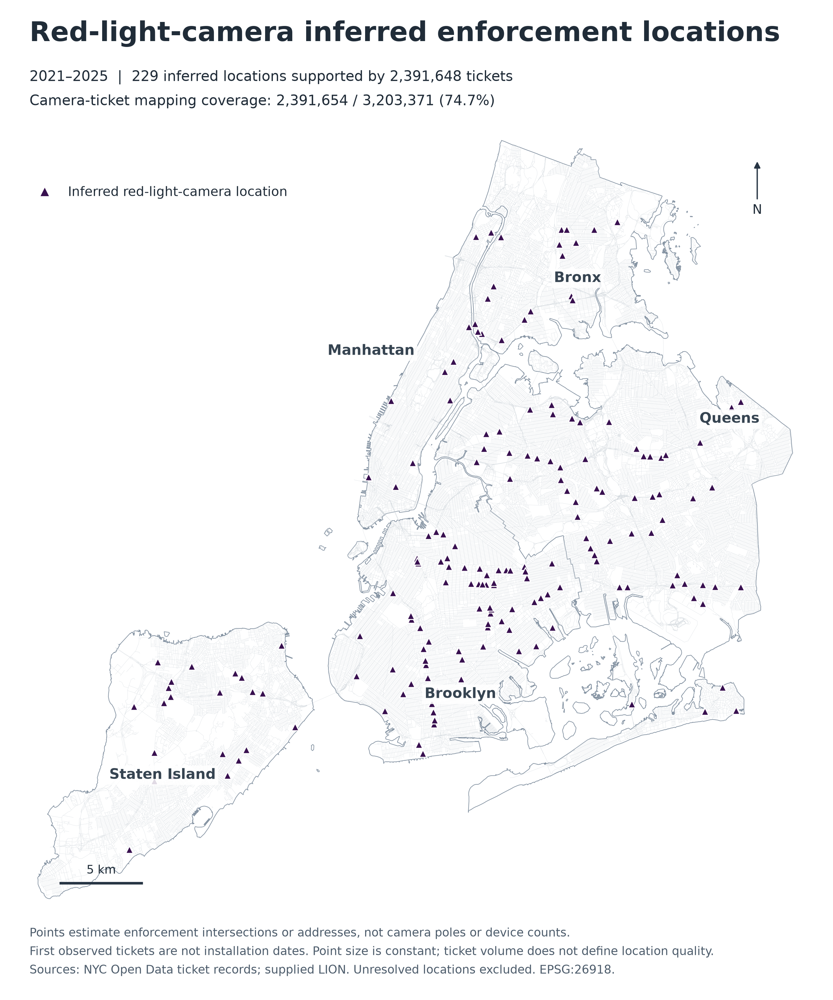

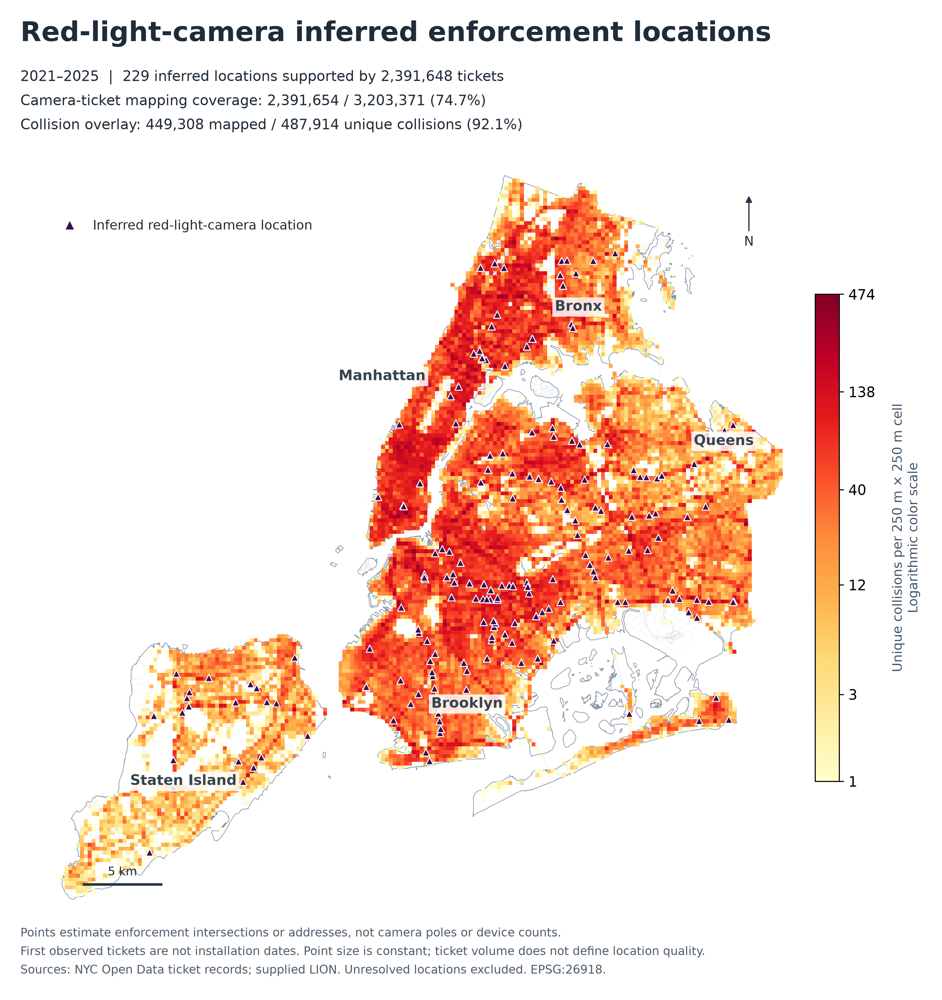

In [11]:
maps.camera_maps()
maps.finish()
for camera_type in ['speed', 'red_light']:
    for suffix in ['', '_collision_overlay']:
        display(Image(filename=str(ROOT / f'outputs/maps/inferred_{camera_type}_locations{suffix}.png'), width=1000))


### Mapping coverage and missing-location bias

Compare these coverage values before comparing hotspots across years or boroughs. Borough labels use the reported borough, supplemented by unique spatial/address inference when available. Unknown boroughs remain explicit. Missing locations cannot be assigned to the map and can distort spatial comparisons; there is no basis here to assume they are missing at random.

year,2025_minus_2021_pp
measure,
crashes,5.41
persons,6.71
tickets_all,1.68
tickets_red_light,-3.54
tickets_speed,-0.73
vehicles,5.43


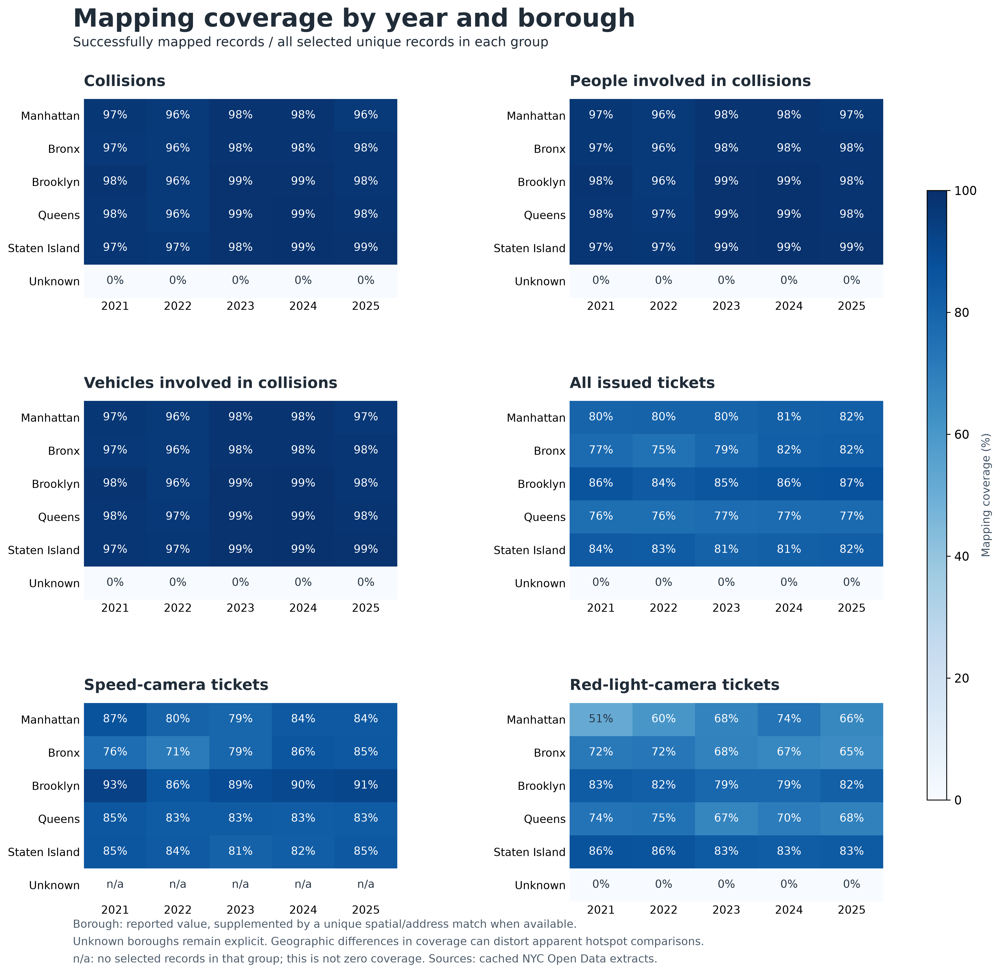

**Coverage assessment:** Across 2021–2025, all-ticket coverage ranges from 76.7% in Queens to 85.8% in Brooklyn. This uneven spatial selection means lower mapped density cannot be interpreted as fewer underlying violations. No missingness correction or exposure adjustment is applied.

In [12]:
coverage_table = borough_coverage.pivot_table(index=['measure','borough'], columns='year', values='mapping_coverage')
display(coverage_table.style.format('{:.1%}', na_rep='Not available'))
coverage_change = annual.pivot(index='measure', columns='year', values='mapping_coverage')
coverage_change['2025_minus_2021_pp'] = (coverage_change[2025] - coverage_change[2021]) * 100
display(coverage_change[['2025_minus_2021_pp']].round(2))
failures = pd.concat([pd.read_csv(QUALITY / 'collision_mapping_coverage.csv'), pd.read_csv(QUALITY / 'ticket_mapping_coverage.csv')])
display(failures[failures.status.ne('mapped')].groupby(['measure','status'])['count'].sum().to_frame().style.format('{:,.0f}'))
from make_coverage_figure import draw
display(Image(filename=str(draw()), width=1150))
ticket_boroughs = borough_coverage[(borough_coverage.measure == 'tickets_all') & (borough_coverage.borough != 'Unknown')].groupby('borough')[['count','mapped_count']].sum()
ticket_boroughs['coverage'] = ticket_boroughs.mapped_count / ticket_boroughs['count']
lo, hi = ticket_boroughs.coverage.idxmin(), ticket_boroughs.coverage.idxmax()
display(Markdown(f'**Coverage assessment:** Across 2021–2025, all-ticket coverage ranges from '
    f'{ticket_boroughs.loc[lo, "coverage"]:.1%} in {lo} to {ticket_boroughs.loc[hi, "coverage"]:.1%} in {hi}. '
    'This uneven spatial selection means lower mapped density cannot be interpreted as fewer underlying violations. '
    'No missingness correction or exposure adjustment is applied.'))


### Camera-location desk review

The review sample covers both camera types and all five boroughs, includes low- and high-volume candidates, and uses a fixed seed for the remaining locations. The atlas compares original ticket text with the named LION streets, shared nodes, estimated coordinates, and direction labels. Codex visually inspected the atlas for all 100 selected locations. This is AI-assisted desk review, not independent human or field validation of camera hardware. No coordinate mismatches were identified in the reviewed sample; one Saint John normalization-label issue is documented in the register. This does not establish an external geocoding accuracy rate. Errors and corrections, if any, are recorded in the review register.

In [13]:
review = pd.read_csv(QUALITY / 'manual_review/review_register.csv')
import hashlib
review_manifest = json.loads((QUALITY / 'manual_review/review_manifest.json').read_text())
assert review_manifest['candidate_csv_sha256'] == hashlib.sha256((ROOT / 'outputs/inferred_camera_locations.csv').read_bytes()).hexdigest()
assert review_manifest['geocoder_sha256'] == hashlib.sha256((ROOT / 'geocode.py').read_bytes()).hexdigest()
display(review.groupby(['camera_type','borough','review_status']).size().to_frame('reviewed_locations'))
reviewed = review.review_status.ne('pending').sum()
assert reviewed >= min(100, len(sites)), 'Manual review is incomplete.'
display(review[['review_number','camera_type','borough','primary_street','cross_street','enforcement_direction','review_status','review_notes']].head(12))


reviewed_locations
camera_type borough       review_status                                     
red_light   Bronx         accepted_intersection_estimate                  10
            Brooklyn      accepted_intersection_estimate                  10
            Manhattan     accepted_intersection_estimate                  10
            Queens        accepted_intersection_estimate                  10
            Staten Island accepted_intersection_estimate                  10
speed       Bronx         accepted_intersection_estimate                  10
            Brooklyn      accepted_intersection_estimate                  10
            Manhattan     accepted_intersection_estimate                  10
            Queens        accepted_intersection_estimate                  10
            Staten Island accepted_intersection_estimate                  10

,review_number,camera_type,borough,primary_street,cross_street,enforcement_direction,review_status,review_notes
0,1,red_light,Bronx,PELHAM PARKWAY NORTH,WILLIAMSBRIDGE ROAD,WB,accepted_intersection_estimate,Original ticket text and plotted named LION st...
1,2,red_light,Bronx,EXTERIOR STREET,EAST 138 STREET,SB,accepted_intersection_estimate,Original ticket text and plotted named LION st...
2,3,red_light,Bronx,BRUCKNER BOULEVARD,LONGWOOD AVENUE,NB,accepted_intersection_estimate,Original ticket text and plotted named LION st...
3,4,red_light,Bronx,LINCOLN AVENUE,EAST 135 STREET,NB,accepted_intersection_estimate,Original ticket text and plotted named LION st...
4,5,red_light,Bronx,WHITE PLAINS ROAD,WATSON AVENUE,SB,accepted_intersection_estimate,Original ticket text and plotted named LION st...
5,6,red_light,Bronx,BARTOW AVENUE,CO OP CITY BOULEVARD,EB,accepted_intersection_estimate,Original ticket text and plotted named LION st...
6,7,red_light,Bronx,BOSTON ROAD,PELHAM PARKWAY,NB,accepted_intersection_estimate,Original ticket text and plotted named LION st...
7,8,red_light,Bronx,GRAND CONCOURSE,EAST 162 STREET,NB,accepted_intersection_estimate,Original ticket text and plotted named LION st...
8,9,red_light,Bronx,WEST FORDHAM ROAD,CEDAR AVENUE,WB,accepted_intersection_estimate,Original ticket text and plotted named LION st...
9,10,red_light,Bronx,EAST 135 STREET,ALEXANDER AVENUE,WB,accepted_intersection_estimate,Original ticket text and plotted named LION st...


## Takeaways

Use these maps to describe recorded-event concentrations and identify locations for further validation. Do not interpret the overlap between tickets and collisions as a camera effect. Camera sites were not randomly selected, and ticket volume also depends on enforcement rules, operating hours, traffic volume, compliance, and reporting.

For future siting or causal work, first obtain independently validated site/activation records and traffic-exposure measures; distinguish speed and red-light mechanisms; then define outcomes, comparable controls, and a pre-specified design. First observed ticket dates in this notebook only describe activity within 2021–2025.

In [14]:
display(Markdown(f'**Delivery check:** {len(sites):,} inferred enforcement locations; '
    f'{int(reviewed):,} locations desk-reviewed; {validation["passed"]:,} automated reconciliation checks passed.'))
display(Markdown('**Exports:** `outputs/maps/` (300 dpi PNG); `outputs/inferred_camera_locations.csv`; '
    '`outputs/inferred_camera_locations.geojson`; `outputs/quality/`; `outputs/data_dictionary.csv`.'))


**Delivery check:** 2,822 inferred enforcement locations; 100 locations desk-reviewed; 377 automated reconciliation checks passed.

**Exports:** `outputs/maps/` (300 dpi PNG); `outputs/inferred_camera_locations.csv`; `outputs/inferred_camera_locations.geojson`; `outputs/quality/`; `outputs/data_dictionary.csv`.